Dimensões do dataset: (61594, 5)

Primeiras avaliações:
        Time_submitted                                             Review  \
0  2022-07-09 15:00:00  Great music service, the audio is high quality...   
1  2022-07-09 14:21:22  Please ignore previous negative rating. This a...   
2  2022-07-09 13:27:32  This pop-up "Get the best Spotify experience o...   
3  2022-07-09 13:26:45    Really buggy and terrible to use as of recently   
4  2022-07-09 13:20:49  Dear Spotify why do I get songs that I didn't ...   

   Rating  Total_thumbsup Reply  
0       5               2   NaN  
1       5               1   NaN  
2       4               0   NaN  
3       1               1   NaN  
4       1               1   NaN  

Distribuição dos sentimentos:
Sentiment
Positivo    29937
Negativo    24771
Neutro       6886
Name: count, dtype: int64

Quantidade de dados para treinamento: 49275
Quantidade de dados para teste: 12319
              precision    recall  f1-score   support

    Negativo      

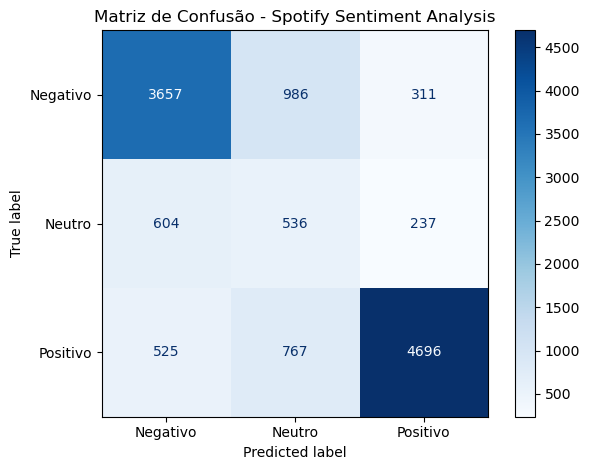


Modelo salvo com sucesso!

========== TESTE DE NOVAS AVALIAÇÕES ==========

AVALIAÇÃO 1
--------------------------------------------------
Texto: Spotify is a bad app.
Sentimento previsto: Negativo

Probabilidades:
Negativo: 71.43%
Neutro: 16.32%
Positivo: 12.25%


In [ ]:

# ============================================
# 1. IMPORTAÇÃO DAS BIBLIOTECAS
# ============================================

import pandas as pd
import joblib
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score
)


# ============================================
# 2. CARREGAMENTO DO DATASET
# ============================================

df = pd.read_csv(
    r"C:\Users\nando\Desktop\spotify-sentiment-analysis\dataset\reviews.csv"
)

print("Dimensões do dataset:", df.shape)
print("\nPrimeiras avaliações:")
print(df.head())


# ============================================
# 3. PREPARAÇÃO DOS DADOS
# ============================================

# Remover registros sem rating
df = df.dropna(subset=["Rating"])

# Garantir que os ratings sejam inteiros
df["Rating"] = df["Rating"].astype(int)

# Remover avaliações duplicadas ou vazias
df = df.dropna(subset=["Review"])
df = df[df["Review"].str.strip() != ""]

# Separar avaliações com ratings válidos
df = df[df["Rating"].between(1, 5)].copy()


# ============================================
# 4. CLASSIFICAÇÃO DOS SENTIMENTOS
# ============================================

def classificar_sentimento(rating):

    if rating <= 2:
        return "Negativo"

    elif rating == 3:
        return "Neutro"

    else:
        return "Positivo"


df["Sentiment"] = df["Rating"].apply(classificar_sentimento)


# Visualizar distribuição das classes

print("\nDistribuição dos sentimentos:")
print(df["Sentiment"].value_counts())


# ============================================
# 5. SEPARAÇÃO DAS VARIÁVEIS
# ============================================

X = df["Review"].fillna("")
y = df["Sentiment"]


# ============================================
# 6. DIVISÃO DOS DADOS
# ============================================

X_train, X_test, y_train_sentiment, y_test_sentiment = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nQuantidade de dados para treinamento:", len(X_train))
print("Quantidade de dados para teste:", len(X_test))


# ============================================
# 7. CRIAÇÃO DO PIPELINE
# ============================================


from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB

# Criar uma lista de stopwords preservando negações
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

stopwords_personalizadas = list(
    ENGLISH_STOP_WORDS.difference({
        "not",
        "no",
        "nor",
        "never",
        "neither"
    })
)

# Criar novo modelo
modelo_sentiment = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        stop_words=stopwords_personalizadas,
        max_features=10000,
        ngram_range=(1, 2),
        sublinear_tf=True
    )),

    ("naive_bayes", MultinomialNB(
        alpha=0.5,
        fit_prior=False
    ))
])

# Treinar novamente
modelo_sentiment.fit(X_train, y_train_sentiment)

# Avaliar
pred_sentiment = modelo_sentiment.predict(X_test)

print(classification_report(
    y_test_sentiment,
    pred_sentiment
))


# modelo_sentiment = Pipeline([

#     # Transformação dos textos em vetores numéricos
#     ("tfidf", TfidfVectorizer(
#         lowercase=True,
#         stop_words="english",
#         max_features=5000
#     )),

#     # Classificador Naive Bayes
#     ("naive_bayes", MultinomialNB(
#         alpha=0.5,
#         fit_prior=False
#     ))

# ])


# ============================================
# 8. TREINAMENTO DO MODELO
# ============================================

modelo_sentiment.fit(
    X_train,
    y_train_sentiment
)

print("\nModelo treinado com sucesso!")


# ============================================
# 9. REALIZAÇÃO DAS PREVISÕES
# ============================================

pred_sentiment = modelo_sentiment.predict(X_test)


# ============================================
# 10. AVALIAÇÃO DO MODELO
# ============================================

accuracy = accuracy_score(
    y_test_sentiment,
    pred_sentiment
)

f1_macro = f1_score(
    y_test_sentiment,
    pred_sentiment,
    average="macro"
)

f1_weighted = f1_score(
    y_test_sentiment,
    pred_sentiment,
    average="weighted"
)

print("\n========== RESULTADOS ==========")

print(f"Accuracy: {accuracy:.4f}")
print(f"F1 Macro: {f1_macro:.4f}")
print(f"F1 Weighted: {f1_weighted:.4f}")

print("\nClassification Report:")

print(classification_report(
    y_test_sentiment,
    pred_sentiment
))


# ============================================
# 11. MATRIZ DE CONFUSÃO
# ============================================

matriz = confusion_matrix(
    y_test_sentiment,
    pred_sentiment,
    labels=["Negativo", "Neutro", "Positivo"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=["Negativo", "Neutro", "Positivo"]
)

disp.plot(cmap="Blues")

plt.title("Matriz de Confusão - Spotify Sentiment Analysis")
plt.tight_layout()
plt.show()


# ============================================
# 12. SALVAMENTO DO MODELO
# ============================================

joblib.dump(
    modelo_sentiment,
    "spotify_sentiment_model.pkl"
)

print("\nModelo salvo com sucesso!")


# ============================================
# 13. TESTE COM UMA NOVA AVALIAÇÃO
# ============================================

# nova_avaliacao = [
#     "Spotify is amazing! I love listening to music here."
# ]


# ============================================
# TESTE COM NOVAS AVALIAÇÕES
# ============================================

avaliacoes = [
    "Spotify is boring. I don't like the interface and the music selection is limited.",
    "I love Spotify! It is the best music app ever.",
    "The app is okay, nothing special.",
    "Spotify keeps crashing. This is very disappointing.",
    "The music selection is good, but the interface could be better.",
    "I am very happy with Spotify. Everything works perfectly."
]

print("\n========== TESTE DE NOVAS AVALIAÇÕES ==========")

for i, texto in enumerate(avaliacoes, start=1):

    # Previsão do sentimento
    previsao = modelo_sentiment.predict([texto])[0]

    # Probabilidades por classe
    probabilidades = modelo_sentiment.predict_proba([texto])[0]

    print(f"\nAVALIAÇÃO {i}")
    print("-" * 50)

    print("Texto:", texto)
    print("Sentimento previsto:", previsao)

    print("\nProbabilidades:")

    for classe, probabilidade in zip(
        modelo_sentiment.classes_,
        probabilidades
    ):
        print(f"{classe}: {probabilidade:.2%}")

